# 06 · Generación fotovoltaica estimada en cada parque
Con la GHI satelital del píxel de cada parque:

**GHI** → modelo de Erbs (**DNI** y **DHI**) → irradiancia en el plano del panel → **PVWatts** (potencia DC, con temperatura de celda de Faiman) → inversor → **potencia AC**.

Además, para cada hora se registra:
- si el parque está **bajo un SCM**,
- la **distancia al SCM más cercano**,
- la **etapa** del ciclo de vida del sistema.

**Salida:** `datos/procesados/fv_parques_horario.csv`

⚠️ El diseño real del parque (estructura fija o seguidor, inclinación) no se conoce con certeza. Este es un modelo genérico; la comparación con XM (notebook 08) dirá qué tan bueno es.

In [1]:
# ▶ CELDA DE PREPARACIÓN — ejecútala siempre de primera
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # En Colab los archivos se guardan en tu Google Drive para no perderlos
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/scm_magdalena")   # cámbiala si quieres
    CARPETA.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA)
    PAQUETES = ["numpy", "scipy", "pandas", "xarray", "dask", "netCDF4", "h5netcdf", "s3fs", "pyproj", "shapely", "geopandas", "rasterio", "pvlib", "pydataxm", "libpysal", "esda", "matplotlib"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES], check=True)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())
assert Path("config.py").exists(), "No encuentro config.py: ejecuta primero el notebook 00 en esta misma carpeta"

Carpeta de trabajo: c:\Users\User\Desktop\Unal\Analisis Geoespacial\notebooks_scm_magdalena


In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import pvlib
from scipy import ndimage
import matplotlib.pyplot as plt
import config as C

irr = xr.open_mfdataset(sorted(C.PROC.glob("irradiancia_*.nc")))
mask = xr.open_dataset(C.PROC / "scm_mascara.nc")["scm_id"]
tray = pd.read_csv(C.PROC / "scm_trayectorias.csv", parse_dates=["time"])
etapa = tray.set_index(["scm_id", "time"])["etapa"]
parques = gpd.read_file(C.PROC / "parques.gpkg")

## 1. Distancia de cada píxel al SCM más cercano, por hora

In [3]:
km_por_pix = C.RES_MALLA * 111.0
t_comun = np.intersect1d(irr.time.values, mask.time.values)
m = mask.sel(time=t_comun).values
dist = np.stack([ndimage.distance_transform_edt(mi == 0) * km_por_pix if mi.any()
                 else np.full(mi.shape, np.inf) for mi in m])
print("Horas diurnas analizadas:", len(t_comun))

Horas diurnas analizadas: 21


## 2. Modelo PVWatts en cada parque

In [4]:
salidas = []
for _, p in parques.iterrows():
    s = irr.sel(lat=p.lat, lon=p.lon, method="nearest").sel(time=t_comun).to_dataframe()[["kc", "ghi", "ghi_despejado"]]
    s.index = pd.DatetimeIndex(s.index).tz_localize("UTC")
    sol = pvlib.solarposition.get_solarposition(s.index, p.lat, p.lon)
    ghi = s.ghi.fillna(0)
    dec = pvlib.irradiance.erbs(ghi, sol.zenith, s.index)
    poa = pvlib.irradiance.get_total_irradiance(C.INCLINACION, C.AZIMUT, sol.apparent_zenith, sol.azimuth,
                                                dec["dni"], ghi, dec["dhi"])
    tcel = pvlib.temperature.faiman(poa["poa_global"], C.T_AIRE_C, C.VIENTO_MS)
    pdc = pvlib.pvsystem.pvwatts_dc(poa["poa_global"], tcel, p.capacidad_mw, C.GAMMA_PDC)
    s["p_ac_mw"] = np.clip(pdc * C.EFIC_INVERSOR, 0, p.capacidad_mw).where(s.ghi.notna())
    iy = int(np.abs(irr.lat.values - p.lat).argmin()); ix = int(np.abs(irr.lon.values - p.lon).argmin())
    s["scm_id"] = m[:, iy, ix]
    s["bajo_scm"] = s["scm_id"] > 0
    s["dist_scm_km"] = dist[:, iy, ix]
    s["etapa"] = [etapa.get((int(i), t.tz_localize(None)), "") if i > 0 else "" for i, t in zip(s.scm_id, s.index)]
    s["parque"] = p.nombre
    salidas.append(s.reset_index())

fv = pd.concat(salidas)
fv.to_csv(C.PROC / "fv_parques_horario.csv", index=False)
fv.groupby(["parque", "bajo_scm"])[["kc", "p_ac_mw"]].mean().round(3)

,,kc,p_ac_mw
parque,bajo_scm,,
Caimán Cienaguero,False,0.819,6.537
Parque Solar Fundación (Enel),False,0.934,50.446


## 3. Serie de tiempo con los SCM marcados

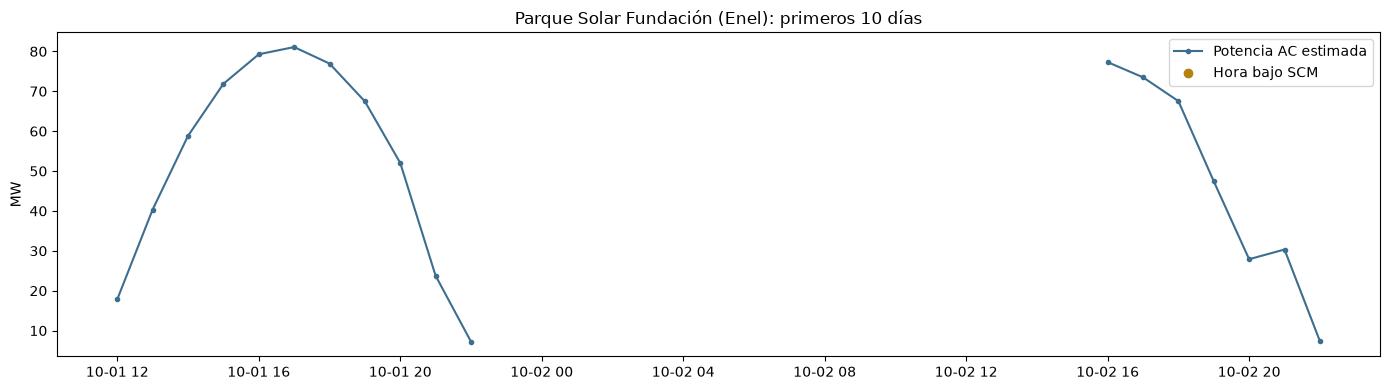

In [5]:
p0 = parques.iloc[0]["nombre"]
d = fv[fv.parque == p0].set_index("time").iloc[:13 * 10]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(d.index, d.p_ac_mw, "o-", ms=3, color="#3D6E8F", label="Potencia AC estimada")
ax.scatter(d.index[d.bajo_scm], d.p_ac_mw[d.bajo_scm], color="#B5810F", zorder=3, label="Hora bajo SCM")
ax.set_ylabel("MW"); ax.set_title(f"{p0}: primeros 10 días"); ax.legend()
plt.tight_layout(); plt.show()

✅ Sigue con el notebook **07**.